In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent          
sys.path.append(str(ROOT)) 

import numpy as np
import preprocessing as prep
import matplotlib.pyplot as plt
import implementations as impl
from helpers import load_csv_data
from newton import *



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(str(ROOT / "data" / "dataset"))

names = prep.load_feature_names(str(ROOT / "data" / "dataset" / "x_train.csv"))
x_tr, x_va, y_tr, y_va = prep.split_data(x_train, y_train, ratio=0.8, seed=1)

X_tr, X_va, X_te, feature_names, params = prep.preprocess_split(x_tr, x_va, x_test, names)
tx_tr, tx_va, tx_te = prep.add_bias(X_tr, X_va, X_te)



train (262508, 118) | validation (65627, 118) | test (109379, 118)


In [10]:
y_tr01 = (y_tr == 1).astype(float)
y_va01 = (y_va == 1).astype(float)

In [12]:
initial_w = np.zeros(tx_tr.shape[1])
max_iters = 100
gamma = 0.1

w, loss = logistic_regression_newton(y_tr01, tx_tr, initial_w, max_iters, gamma)

In [13]:
"""Évaluation et visualisation d'un classifieur linéaire (régression logistique).

Utilisation dans le notebook :
    import evaluation as ev
    res = ev.evaluate(y_va, tx_va, w)            # métriques + graphes
    pred_te = ev.predict(tx_te, w, res["best_threshold"])   # prédictions -1/1
"""

import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------------------------------
# Métriques
# ---------------------------------------------------------------------------
def to01(y):
    """Convertit des labels -1/1 (ou 0/1) en 0/1."""
    return (np.asarray(y).ravel() == 1).astype(int)


def confusion(y01, pred01):
    """Renvoie TP, FP, FN, TN."""
    tp = int(np.sum((pred01 == 1) & (y01 == 1)))
    fp = int(np.sum((pred01 == 1) & (y01 == 0)))
    fn = int(np.sum((pred01 == 0) & (y01 == 1)))
    tn = int(np.sum((pred01 == 0) & (y01 == 0)))
    return tp, fp, fn, tn


def metrics(y01, pred01):
    """Accuracy, precision, recall et F1 (classe positive = 1)."""
    tp, fp, fn, tn = confusion(y01, pred01)
    accuracy = (tp + tn) / len(y01)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def f1_vs_threshold(y01, scores, n=300):
    """F1 pour une grille de seuils sur les scores t = x·w."""
    lo, hi = np.percentile(scores, [0.5, 99.5])
    thresholds = np.linspace(lo, hi, n)
    f1s = np.array([metrics(y01, (scores > t).astype(int))["f1"] for t in thresholds])
    return thresholds, f1s


def predict(tx, w, threshold=0.0, labels=(-1, 1)):
    """Prédictions finales dans le format de la soumission (par défaut -1/1)."""
    return np.where(tx @ w > threshold, labels[1], labels[0])


# ---------------------------------------------------------------------------
# Évaluation complète + graphes
# ---------------------------------------------------------------------------
def evaluate(y, tx, w, save_name=None, show=True):
    """Calcule les métriques au seuil 0 et au meilleur seuil (F1) et trace 3 graphes.

    y  : labels (-1/1 ou 0/1) du set évalué (idéalement la validation)
    tx : données avec colonne de biais, même prétraitement que pour l'entraînement
    w  : poids appris
    """
    y01 = to01(y)
    scores = tx @ w

    # Seuil par défaut : sigmoid(t) > 0.5  <=>  t > 0
    m0 = metrics(y01, (scores > 0).astype(int))

    # Meilleur seuil pour le F1
    thresholds, f1s = f1_vs_threshold(y01, scores)
    best_t = float(thresholds[np.argmax(f1s)])
    mb = metrics(y01, (scores > best_t).astype(int))

    # ---- Affichage texte
    print(f"Proportion de classe 1 : {y01.mean():.3f}")
    print(f"{'':22s}{'seuil 0':>12s}{'meilleur seuil':>17s}")
    print(f"{'seuil sur t = x·w':22s}{0.0:12.3f}{best_t:17.3f}")
    for k in ["accuracy", "precision", "recall", "f1"]:
        print(f"{k:22s}{m0[k]:12.4f}{mb[k]:17.4f}")

    # ---- Graphes
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # 1) Distribution des scores par classe
    ax = axes[0]
    bins = np.linspace(*np.percentile(scores, [0.5, 99.5]), 80)
    ax.hist(scores[y01 == 0], bins=bins, alpha=0.5, density=True, label="classe 0", color="tab:red")
    ax.hist(scores[y01 == 1], bins=bins, alpha=0.5, density=True, label="classe 1", color="tab:blue")
    ax.axvline(0, color="k", ls="--", lw=1, label="seuil 0")
    ax.axvline(best_t, color="tab:green", ls="--", lw=1.5, label=f"meilleur seuil ({best_t:.2f})")
    ax.set_xlabel("score t = x·w")
    ax.set_ylabel("densité")
    ax.set_title("Distribution des scores")
    ax.legend()

    # 2) F1 en fonction du seuil
    ax = axes[1]
    ax.plot(thresholds, f1s, color="tab:green")
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.axvline(best_t, color="tab:green", ls="--", lw=1.5)
    ax.set_xlabel("seuil sur t = x·w")
    ax.set_ylabel("F1")
    ax.set_title(f"F1 vs seuil (max = {mb['f1']:.3f})")
    ax.grid(alpha=0.3)

    # 3) Matrice de confusion au meilleur seuil
    ax = axes[2]
    cm = np.array([[mb["tn"], mb["fp"]], [mb["fn"], mb["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["prédit 0", "prédit 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["vrai 0", "vrai 1"])
    ax.set_title("Matrice de confusion (meilleur seuil)")

    plt.tight_layout()
    if save_name:
        plt.savefig(save_name + ".png", dpi=150)
    if show:
        plt.show()

    return {"default": m0, "best": mb, "best_threshold": best_t}

Proportion de classe 1 : 0.088
                           seuil 0   meilleur seuil
seuil sur t = x·w            0.000           -1.399
accuracy                    0.9145           0.8715
precision                   0.5649           0.3528
recall                      0.1396           0.5460
f1                          0.2239           0.4286


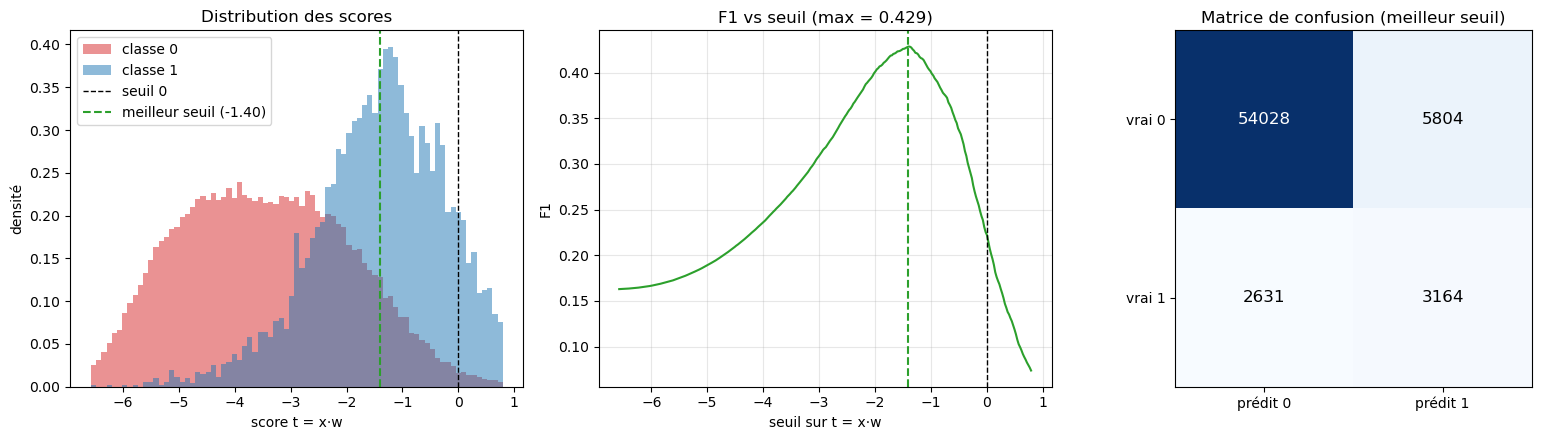

In [14]:
res = evaluate(y_va, tx_va, w, save_name="newton_eval")

In [15]:
from helpers import create_csv_submission
pred_te = predict(tx_te, w, res["best_threshold"])

# 2. Vérifications rapides
print(len(pred_te), len(test_ids))       # doivent être égaux (109379)
print(np.unique(pred_te, return_counts=True))

# 3. Création du CSV
create_csv_submission(test_ids, pred_te, str(ROOT / "submission_newton.csv"))

109379 109379
(array([-1,  1]), array([94408, 14971]))
